In [60]:
import os
import pandas as pd
import numpy as np
import matplotlib as plt
import networkx as nx
import mip

BUILDING_NAME = "Edificio2.csv"

ASCENDING_SPEED = 1.0
DESCENDING_SPEED = 2.0
HORIZONTAL_SPEED = 1.5

ASCENDING_ENERGY = 50
DESCENDING_ENERGY = 5
HORIZONTAL_ENERGY = 10

X_BASE_RANGE = range(-8, 6) if "Edificio1.csv" == BUILDING_NAME else range(-10, 11)
Y_BASE_RANGE = range(-17, -14) if "Edificio1.csv" == BUILDING_NAME else range(-31, -29)
Z_BASE = 0

BATTERY_CAPACITY = 3600 if "Edificio1.csv" == BUILDING_NAME else 21600  # 1 Wh is 3600 J

Y_ENTRY_POINT = -12.5 if "Edificio1.csv" == BUILDING_NAME else -20.0

# Reading CSV and creating pairs


In [61]:
# loading building csv data

nodes = pd.read_csv(BUILDING_NAME)

# Creating Bases and entry points

In [62]:
# Adding is_base and is_entry_point columns

nodes["is_base"] = False

nodes["is_entry_point"] = nodes["y"] <= Y_ENTRY_POINT


# Creating new rows for base points
bases = []
for x in X_BASE_RANGE:
    for y in Y_BASE_RANGE:
        bases.append(
            {"x": x, "y": y, "z": Z_BASE, "is_base": True, "is_entry_point": False}
        )

# Appending base rows to the building dataframe
building = pd.concat([nodes, pd.DataFrame(bases)], ignore_index=True)

building.to_csv("building.csv", index=False)

# Merging nodes to create pairs

In [63]:
# setting node numbering from 1 to n
building.index += 1

# generating all possible pairs of points (edges)
nodes_pairs = (
    building.rename_axis("source_node")
    .reset_index()
    .merge(building.rename_axis("target_node").reset_index(), how="cross")
)

# removing self-self pairs
nodes_pairs = nodes_pairs[
    nodes_pairs["source_node"] != nodes_pairs["target_node"]
]  # keeping only pairs with different points

In [64]:
first_point_cols = ["x_x", "y_x", "z_x"]
second_point_cols = ["x_y", "y_y", "z_y"]
diff_cols = ["dx", "dy", "dz"]

# Computing distances 

In [65]:
# function to determine if two points are connected based on distance and coordinate deltas


def process_connections(dataframe):
    # distances and deltas on coordinates
    dataframe[diff_cols] = (
        dataframe[second_point_cols].values - dataframe[first_point_cols].values
    )
    dataframe["euclidean_distance"] = np.sqrt(
        (dataframe[diff_cols] ** 2).sum(axis=1)
    )  # axis=1 sum on columns

    # conditions near and tunnel
    condition_near = dataframe["euclidean_distance"] <= 4.0

    condition_tunnel = (
        ((dataframe["dx"].abs() <= 0.5) & (dataframe["dy"].abs() <= 0.5))
        | ((dataframe["dy"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
        | ((dataframe["dx"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
    )

    condition_tunnel_and_not_far = (
        dataframe["euclidean_distance"] <= 11.0
    ) & condition_tunnel

    # if the arc is from base to entry point or viceversa
    condition_base_to_entry_point = (
        (dataframe["is_base_x"]) & (dataframe["is_entry_point_y"])
    ) | ((dataframe["is_base_y"]) & (dataframe["is_entry_point_x"]))

    # l'unica connessione ammessa è base <-> entry point
    condition_involves_base = dataframe["is_base_x"] | dataframe["is_base_y"]

    # Gli archi tra nodi griglia usano le regole di distanza (near/tunnel)
    # Gli archi con basi usano SOLO la regola base <-> entry point
    dataframe["are_connected"] = (
        (condition_near & ~condition_involves_base)
        | (condition_tunnel_and_not_far & ~condition_involves_base)
        | condition_base_to_entry_point
    )
    return dataframe

In [66]:
nodes_pairs = process_connections(nodes_pairs)

nodes_pairs.to_csv("pairs.csv", index=False)

nodes_pairs.head()

,source_node,x_x,y_x,z_x,is_base_x,is_entry_point_x,target_node,x_y,y_y,z_y,is_base_y,is_entry_point_y,dx,dy,dz,euclidean_distance,are_connected
1,1,-15.7277,-18.288,79.3699,False,False,2,-16.9469,-14.8742,79.3699,False,False,-1.2192,3.4138,0.0,3.624980,True
2,1,-15.7277,-18.288,79.3699,False,False,3,-16.9469,-7.2542,79.3699,False,False,-1.2192,11.0338,0.0,11.100955,False
3,1,-15.7277,-18.288,79.3699,False,False,4,-19.1110,-7.2542,79.3699,False,False,-3.3833,11.0338,0.0,11.540861,False
4,1,-15.7277,-18.288,79.3699,False,False,5,-20.7264,-5.9131,79.3699,False,False,-4.9987,12.3749,0.0,13.346353,False
5,1,-15.7277,-18.288,79.3699,False,False,6,-20.7264,-3.4138,79.3699,False,False,-4.9987,14.8742,0.0,15.691680,False


In [67]:
# computing vertical distances on z and distances on horizontal plane x,y
nodes_pairs["d_horizontal"] = np.sqrt(nodes_pairs["dx"] ** 2 + nodes_pairs["dy"] ** 2)
nodes_pairs["d_vertical"] = nodes_pairs["dz"]

# dropping columns that are not useful anymore
nodes_pairs.drop(columns=["dx", "dy", "dz"], inplace=True)
nodes_pairs.drop(columns=["x_x", "y_x", "z_x", "x_y", "y_y", "z_y"], inplace=True)

# keeping only connected pairs
nodes_pairs = nodes_pairs[nodes_pairs["are_connected"] == True]
nodes_pairs.drop(columns=["are_connected"], inplace=True)

nodes_pairs.head(5)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,euclidean_distance,d_horizontal,d_vertical
1,1,False,False,2,False,False,3.62498,3.62498,0.0000
40,1,False,False,41,False,False,3.84050,3.84050,0.0000
41,1,False,False,42,False,False,4.38910,0.00000,-4.3891
82,1,False,False,83,False,False,9.87550,0.00000,-9.8755
653,1,False,False,654,False,False,7.74190,7.74190,0.0000


# Function for time travel

In [68]:
# finding rows corresponding to different movement types

d_horizontal = nodes_pairs["d_horizontal"]
d_vertical = nodes_pairs["d_vertical"]
rows_horizontal = d_vertical == 0
rows_ascending = (d_horizontal == 0) & (d_vertical > 0)
rows_descending = (d_horizontal == 0) & (d_vertical < 0)
rows_oblique_ascending = (d_horizontal != 0) & (d_vertical > 0)
rows_oblique_descending = (d_horizontal != 0) & (d_vertical < 0)

In [69]:
# function for time travel based on movement types and speeds


def compute_time_travel(dataframe):
    dataframe.loc[rows_horizontal, "time_travel"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] / HORIZONTAL_SPEED
    )

    dataframe.loc[rows_ascending, "time_travel"] = (
        dataframe.loc[rows_ascending, "d_vertical"] / ASCENDING_SPEED
    )
    dataframe.loc[rows_descending, "time_travel"] = (
        -dataframe.loc[rows_descending, "d_vertical"] / DESCENDING_SPEED
    )

    dataframe.loc[rows_oblique_ascending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] / HORIZONTAL_SPEED,
        dataframe.loc[rows_oblique_ascending, "d_vertical"] / ASCENDING_SPEED,
    )

    dataframe.loc[rows_oblique_descending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_descending, "d_horizontal"] / HORIZONTAL_SPEED,
        -dataframe.loc[rows_oblique_descending, "d_vertical"] / DESCENDING_SPEED,
    )
    return dataframe

# Function for energy consumption


In [70]:
# function for energy cost based on movement types and energy consumption rates


def compute_energy_cost(dataframe):
    dataframe.loc[rows_horizontal, "energy_consumption"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] * HORIZONTAL_ENERGY
    )

    dataframe.loc[rows_ascending, "energy_consumption"] = (
        dataframe.loc[rows_ascending, "d_vertical"] * ASCENDING_ENERGY
    )
    dataframe.loc[rows_descending, "energy_consumption"] = (
        -dataframe.loc[rows_descending, "d_vertical"] * DESCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_ascending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] * HORIZONTAL_ENERGY
        + dataframe.loc[rows_oblique_ascending, "d_vertical"] * ASCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_descending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_descending, "d_horizontal"] * HORIZONTAL_ENERGY
        + -dataframe.loc[rows_oblique_descending, "d_vertical"] * DESCENDING_ENERGY
    )
    return dataframe

# Actually computing energy and time costs for arcs

In [71]:
# computing time travel and energy cost for each pair (edges)

nodes_pairs = compute_time_travel(nodes_pairs)

nodes_pairs = compute_energy_cost(nodes_pairs)

nodes_pairs.drop(
    columns=["d_horizontal", "d_vertical", "euclidean_distance"], inplace=True
)

nodes_pairs.head(10)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,time_travel,energy_consumption
1,1,False,False,2,False,False,2.416653,36.249799
40,1,False,False,41,False,False,2.560333,38.405000
41,1,False,False,42,False,False,2.194550,21.945500
82,1,False,False,83,False,False,4.937750,49.377500
653,1,False,False,654,False,False,5.161267,77.419000
738,2,False,False,1,False,False,2.416653,36.249799
740,2,False,False,3,False,False,5.080000,76.200000
780,2,False,False,43,False,False,2.194550,21.945500
821,2,False,False,84,False,False,4.937750,49.377500
1477,3,False,False,2,False,False,5.080000,76.200000


# Creating Graph with Networkx


In [72]:
# creating directed graph G from the dataframe of edges with costs

G = nx.from_pandas_edgelist(
    nodes_pairs,  # dataframe containing edges
    source="source_node",  # indicating the start of the edge
    target="target_node",  # indicating the end of the edge
    edge_attr=["time_travel", "energy_consumption"],  # edge costs
    create_using=nx.DiGraph(),  # creating an oriented graph
)



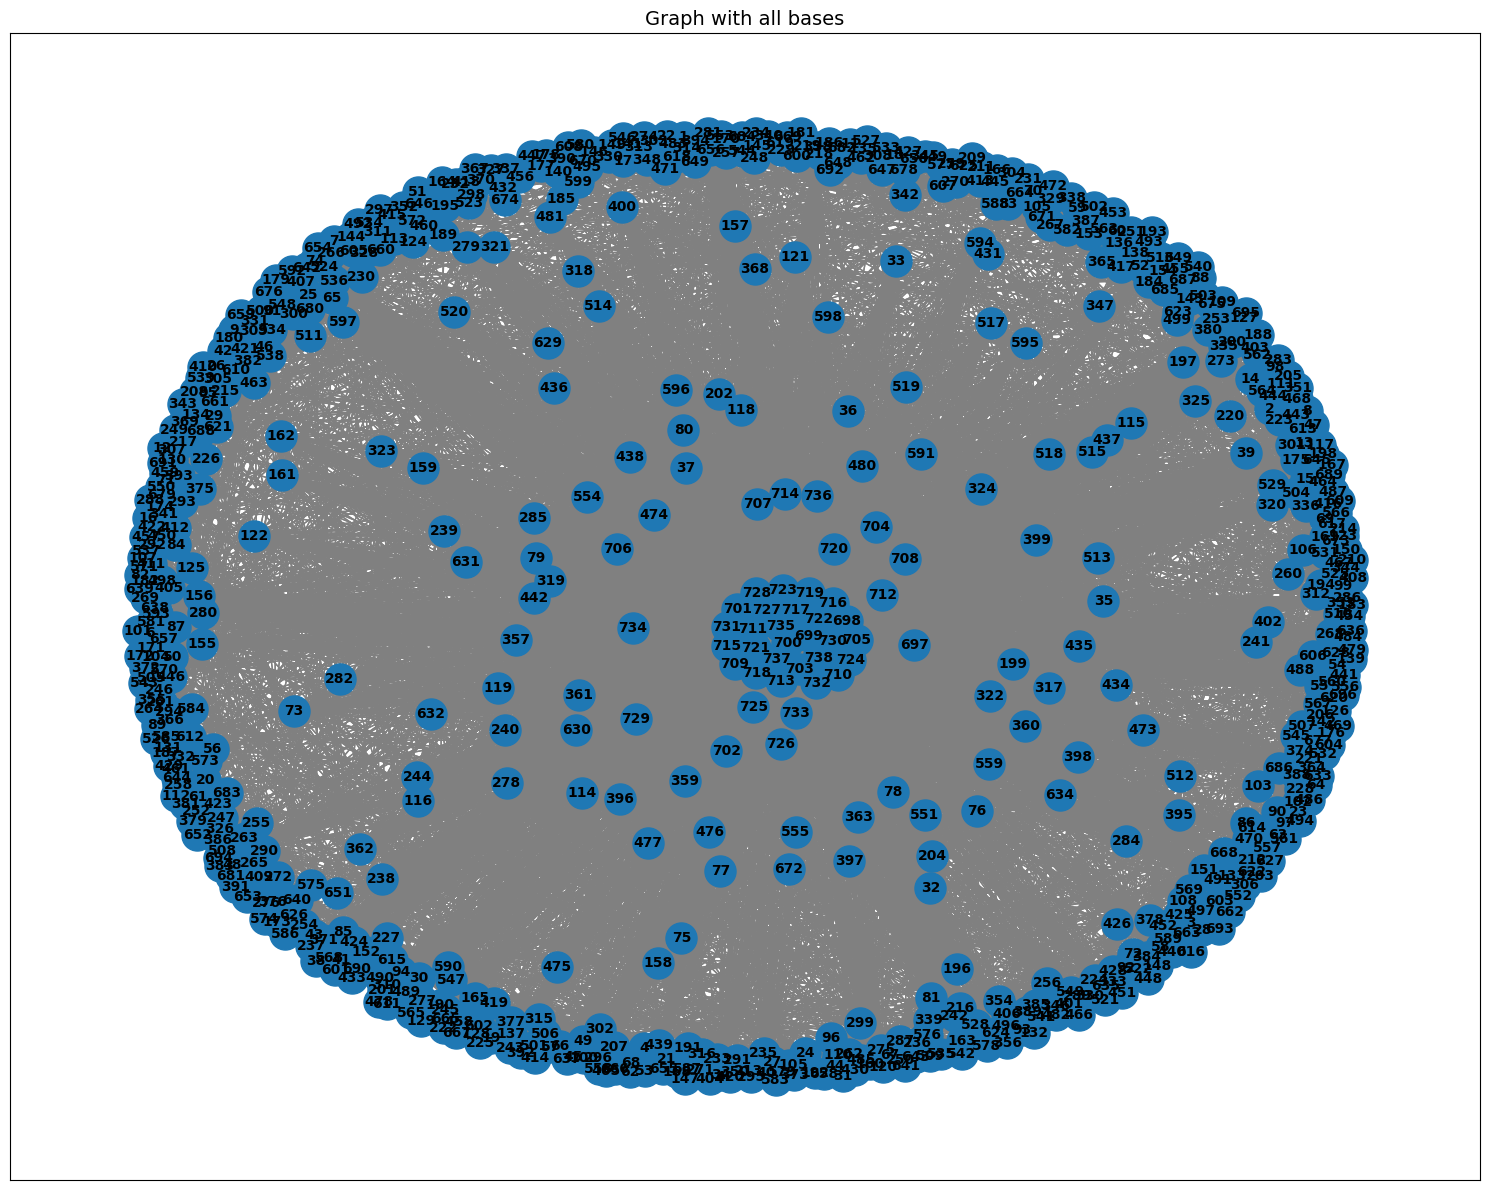

In [73]:
import matplotlib.pyplot as plt

#creo una lista delle basi da rimuovere 


#print(basi_da_rimuovere)

#creo il grafo senza le basi
G_sub = G.copy()

plt.figure(figsize=(15, 12))

# k controlla la distanza tra i nodi 
pos = nx.spring_layout(G_sub, k=2.5, iterations=100, seed=42)




nx.draw_networkx(
    G_sub, 
    pos=pos, 
    node_size=500,  
    font_size=10,           
    font_weight='bold',
    edge_color='gray',
    arrows=True,
    arrowsize=15
)

plt.title(f"Graph with all bases", fontsize=14)
#plt.legend()
plt.tight_layout()
plt.show()


# MODELLO MIP

In [74]:
# IL DATAFRAME BASES CONTIENE TUTTE LE BASI
# IL DATAFRAME NODES CONTIENE I NODI DEL SET S
# IL NODES_PAIRS CONTIENE GLI ARCHI TRA TUTTI I NODI
# IL SET H È UN INSIEME DI NUMERI DA 0 A UN NUMERO k CHE VA STIMATO BENE

m = mip.Model("DroneTourPlanning")

# SETS AND PARAMETERS
# ---------------------------------------------------------------
N = building.index.tolist()  # All nodes
S = building[building["is_base"] == False].index.tolist()  # Service nodes
B = building[building["is_base"] == True].index.tolist()  # Bases nodes
print(f"set N = {N}")
print(f"set B = {B}")
print(f"set S = {S}")

A = G.edges  # set of arcs
print(f"set A = {A}")

t = {
    (u, v): data["time_travel"] for u, v, data in G.edges(data=True)
}  # dictionary of time travel costs
e = {
    (u, v): data["energy_consumption"] for u, v, data in G.edges(data=True)
}  # dictionary of energy consumption costs
print(f"time travel costs t = {t}")
print(f"energy consumption costs e = {e}")

C = BATTERY_CAPACITY  # battery capacity

set N = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220,

# H E BIG M

In [75]:
# Calculate |H| according to formula: ceil(sum(e_in_min + e_out_min)/C * 1.5)
import math

min_energy_in_out = {}
for i in S:
    incoming = [e[j, i] for j in N if (j, i) in A]
    outgoing = [e[i, j] for j in N if (i, j) in A]
    min_energy_in = min(incoming) if incoming else float("inf")
    min_energy_out = min(outgoing) if outgoing else float("inf")
    min_energy_in_out[i] = min_energy_in + min_energy_out

sum_min_energies = sum(min_energy_in_out.values())
H_length = math.ceil((sum_min_energies / BATTERY_CAPACITY))
H = list(range(1, max(2, H_length + 1)))  # At least 1 tour
#worst case is H = 2 in building 2 
#H = [1,2]

print(f"set H = {H}")

set H = [1, 2]


In [76]:
# ---------------------------------------------------------
# OTTIMIZZAZIONE PRELIMINARE: PRUNING DEL GRAFO
# ---------------------------------------------------------
# Obiettivo: Ridurre drasticamente le dimensioni del problema PRIMA di creare il modello.
# 1. Troviamo la base migliore con Metodo CENTROIDE (più bilanciata).
# 2. Rimuoviamo fisicamente dal grafo tutte le altre basi e i relativi archi.
# 3. Aggiorniamo le liste A (archi), N (nodi), t (tempi), e (energie).

import networkx as nx

print("--- PRUNING BASI NON OTTIMALI ---")
print(f"PRIMA -> Basi: {len(B)}, Archi: {len(A) if hasattr(A, '__len__') else 'N/A'}")

# 1. Identifica la Best Base (Metodo Centroide + Connettività)
# Calcoliamo il centroide geometrico dei nodi di servizio S
S_df = building.loc[S]
centroid_x = S_df['x'].mean()
centroid_y = S_df['y'].mean()
centroid_z = S_df['z'].mean()

print(f"Centroide Nodi S: ({centroid_x:.2f}, {centroid_y:.2f}, {centroid_z:.2f})")

best_base_pruning = None
min_dist_to_centroid = float('inf')

# Cerca la base più vicina geometricamente al centroide CHE SIA VALIDA (connessa)
for base_idx in B:
    
    # A. Check Connettività
    # Verifichiamo se la base può raggiungere TUTTI i nodi S
    # Eseguendo un path search
    try:
        lengths = nx.single_source_shortest_path_length(G, source=base_idx)
        if not all(s in lengths for s in S):
            continue # Base scartata perché non connette tutto il grafo
    except:
        continue # Errore nel calcolo path

    # B. Calcola distanza geometrica dal centroide (Euclidea)
    b_row = building.loc[base_idx]
    dist_sq = (b_row['x'] - centroid_x)**2 + \
              (b_row['y'] - centroid_y)**2 + \
              (b_row['z'] - centroid_z)**2
    
    if dist_sq < min_dist_to_centroid:
        min_dist_to_centroid = dist_sq
        best_base_pruning = base_idx

if best_base_pruning is None:
    raise Exception("❌ ERRORE CRITICO: Nessuna base riesce a connettere tutti i nodi!")

print(f"✅ Base Vincitrice (Centroide): {best_base_pruning}")
print(f"distanza quad dal centroide: {min_dist_to_centroid:.2f}")

# 2. Identifica le basi da scartare
bases_to_remove = [b for b in B if b != best_base_pruning]

# 3. Aggiornamento Strutture Dati (Nodi e Grafo)
G.remove_nodes_from(bases_to_remove) # <--- Rimuove nodi E ARCHI incidenti

# Aggiorna le liste dei nodi globali
N = list(G.nodes())                  # N ora non contiene le basi scartate
B = [best_base_pruning]              # B ha solo 1 elemento

# 4. Aggiorna Archi e Costi (Fondamentale per il MIP!)
# A deve essere un SET per lookup veloce nei vincoli: "if (i,j) in A"
# G.edges() restituisce una view, convertirla in lista è lento per i check.
A = set(G.edges())                   # <--- FIX PERFORMANCE: SET invece di LIST

# Rigenera i dizionari dei costi (t ed e) basandosi solo sugli archi esistenti
t = {(u, v): data["time_travel"] for u, v, data in G.edges(data=True)}
e = {(u, v): data["energy_consumption"] for u, v, data in G.edges(data=True)}

print(f"\n--- PULIZIA COMPLETATA ---")
print(f"DOPO  -> Basi: {len(B)} (Solo nodo {B[0]})")
print(f"DOPO  -> Archi: {len(A)} (Structure: Set optimized for lookup)")
print("MIP ora creerà variabili solo per questa configurazione.")

--- PRUNING BASI NON OTTIMALI ---
PRIMA -> Basi: 42, Archi: 16726
Centroide Nodi S: (-2.54, 0.00, 39.45)
✅ Base Vincitrice (Centroide): 712
distanza quad dal centroide: 2456.56

--- PULIZIA COMPLETATA ---
DOPO  -> Basi: 1 (Solo nodo 712)
DOPO  -> Archi: 4672 (Structure: Set optimized for lookup)
MIP ora creerà variabili solo per questa configurazione.


In [77]:
# ---------------------------------------------------------
# ANALISI CONNETTIVITÀ
# ---------------------------------------------------------
print("--- NODI CON PIÙ DI 5 ARCHI USCENTI ---")
count_high_degree = 0

for n in G.nodes():
    # G.out_edges(n) restituisce gli archi uscenti
    out_degree = len(G.out_edges(n))
    
    if out_degree > 5:
        print(f"Nodo {n}: {out_degree} archi uscenti")
        count_high_degree += 1

if count_high_degree == 0:
    print("Nessun nodo ha più di 5 archi uscenti.")
else:
    print(f"Totale nodi ad alta connettività (>5 uscite): {count_high_degree}")

--- NODI CON PIÙ DI 5 ARCHI USCENTI ---
Nodo 83: 6 archi uscenti
Nodo 3: 7 archi uscenti
Nodo 84: 6 archi uscenti
Nodo 4: 7 archi uscenti
Nodo 85: 6 archi uscenti
Nodo 7: 7 archi uscenti
Nodo 8: 7 archi uscenti
Nodo 45: 7 archi uscenti
Nodo 86: 8 archi uscenti
Nodo 6: 6 archi uscenti
Nodo 9: 6 archi uscenti
Nodo 46: 6 archi uscenti
Nodo 87: 7 archi uscenti
Nodo 47: 7 archi uscenti
Nodo 88: 8 archi uscenti
Nodo 11: 7 archi uscenti
Nodo 48: 7 archi uscenti
Nodo 89: 8 archi uscenti
Nodo 49: 7 archi uscenti
Nodo 90: 8 archi uscenti
Nodo 50: 7 archi uscenti
Nodo 91: 8 archi uscenti
Nodo 51: 6 archi uscenti
Nodo 92: 7 archi uscenti
Nodo 12: 7 archi uscenti
Nodo 52: 7 archi uscenti
Nodo 93: 8 archi uscenti
Nodo 94: 6 archi uscenti
Nodo 95: 6 archi uscenti
Nodo 96: 6 archi uscenti
Nodo 97: 6 archi uscenti
Nodo 19: 7 archi uscenti
Nodo 57: 6 archi uscenti
Nodo 98: 7 archi uscenti
Nodo 58: 6 archi uscenti
Nodo 99: 7 archi uscenti
Nodo 100: 6 archi uscenti
Nodo 60: 7 archi uscenti
Nodo 101: 8 arc

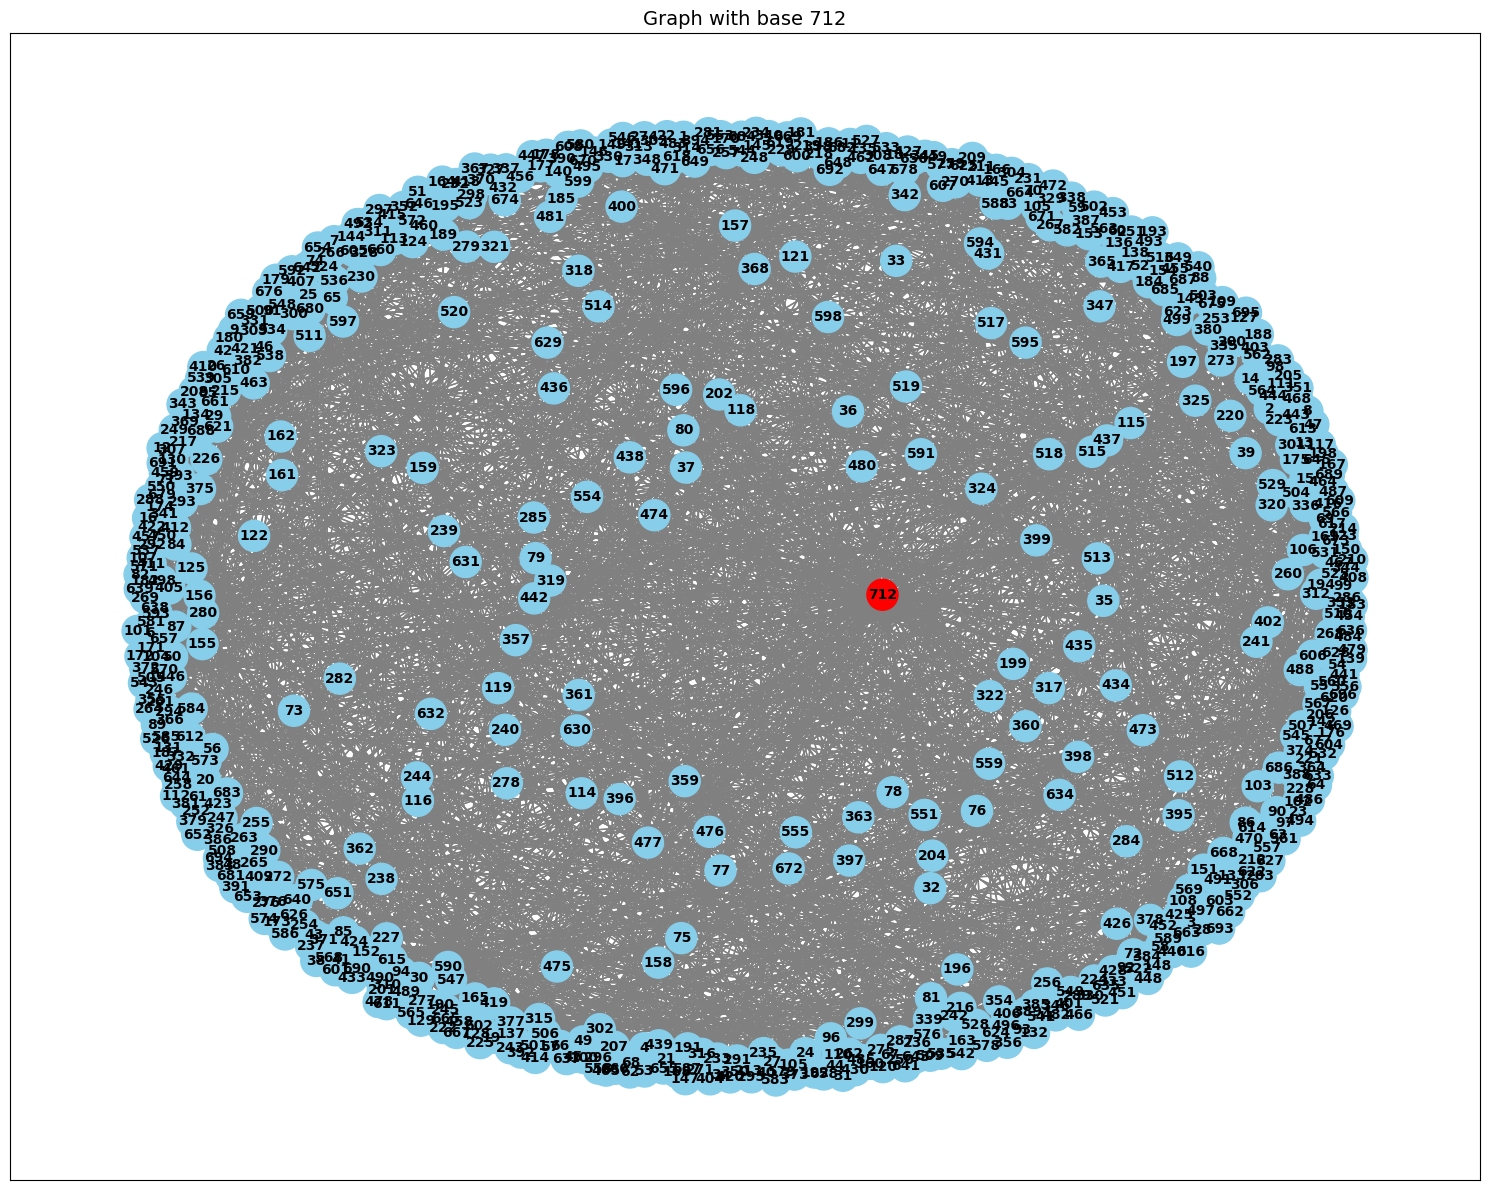

In [78]:
import matplotlib.pyplot as plt

#creo una lista delle basi da rimuovere 


#print(basi_da_rimuovere)

#creo il grafo senza le basi
G_sub = G.copy()

plt.figure(figsize=(15, 12))

# k controlla la distanza tra i nodi 


#colore rosso per la base 
node_colors = ['red' if n == best_base_pruning else 'skyblue' for n in G_sub.nodes()]



nx.draw_networkx(
    G_sub, 
    pos=pos, 
    node_size=500,  
    node_color=node_colors, 
    font_size=10,           
    font_weight='bold',
    edge_color='gray',
    arrows=True,
    arrowsize=15
)

plt.title(f"Graph with base {best_base_pruning}", fontsize=14)
#plt.legend()
plt.tight_layout()
plt.show()

# VARIABILI

In [79]:
# VARIABLES
# ---------------------------------------------------------------
x = {
    (i, j, h): m.add_var(var_type=mip.BINARY, name=f"x_{i}_{j}_{h}")
    for i, j in A
    for h in H
}  # binary variable indicating if arc (i,j) is used in tour h

b = {
    i: m.add_var(var_type=mip.BINARY, name=f"b_{i}") for i in B
}  # binary variable indicating if base i is used

# SCF (Single Commodity Flow) variables for subtour elimination
# f[i,j,h] = flow on arc (i,j) in tour h
f = {
    (i, j, h): m.add_var(lb=0, ub=len(S), name=f"f_{i}_{j}_{h}")
    for i, j in A
    for h in H
}

# OBJ FUNCTION


In [80]:
m.objective = mip.minimize(mip.xsum(t[i, j] * x[i, j, h] for i, j in A for h in H))

# CONSTRAINTS

In [81]:
# (1) Only one base is selected
m += mip.xsum(b[i] for i in B) == 1

# (2) Each service node is visited at least once
for i in S:
    m += mip.xsum(x[j, i, h] for j in N for h in H if (j, i) in A) >= 1

# (3) Flow conservation for x (arc variables)
for i in N:
    for h in H:
        m += mip.xsum(x[j, i, h] for j in N if (j, i) in A) == mip.xsum(
            x[i, j, h] for j in N if (i, j) in A
        )

# (4) Trip departs from base only if selected
for base in B:
    for h in H:
        m += mip.xsum(x[base, j, h] for j in N if (base, j) in A) <= b[base]

# (5) Energy constraint
for h in H:
    m += mip.xsum(e[i, j] * x[i, j, h] for (i, j) in A) <= C

# (6) SCF Subtour Elimination
# Idea: il flusso parte dalla base e viene consumato ad ogni nodo visitato.
# Se c'è un sottotour senza base, non ha sorgente di flusso → infeasible.

# (6a) f_ij <= |S| * x_ij (flow only on active arcs)
for i, j in A:
    for h in H:
        m += f[i, j, h] <= len(S) * x[i, j, h]

# (6b) Flow conservation at service nodes: inflow - outflow = 1 if visited
for i in S:
    for h in H:
        inflow = mip.xsum(f[j, i, h] for j in N if (j, i) in A)
        outflow = mip.xsum(f[i, j, h] for j in N if (i, j) in A)
        visits = mip.xsum(x[j, i, h] for j in N if (j, i) in A)
        m += inflow - outflow == visits

# (6c) Flow at bases: la base è sorgente, il flusso netto uscente >= 0
# Non serve vincolo esplicito: i vincoli (6b) impongono già che il flusso
# totale consumato = nodi visitati. La base è l'unica sorgente possibile.

# (7) Symmetry Breaking
for h in range(len(H) - 1):
    m += mip.xsum(x[i, j, H[h]] for (i, j) in A) >= mip.xsum(
        x[i, j, H[h + 1]] for (i, j) in A
    )

In [82]:
# ---------------------------------------------------------
# ALGORITMO GREEDY ROBUSTO 3.0 (FIX 'AttributeError' + ISOLATED NODES)
# ---------------------------------------------------------

def solve_greedy_heuristic(nodes_to_visit, base_idx, available_tours, capacity_limit):
    import networkx as nx
    
    # 1. ANALISI CONNETTIVITÀ S-to-S (Cruciale!)
    # Creiamo il grafo ridotto ai soli nodi di servizio per vedere se ci sono "isole"
    # che richiedono obbligatoriamente un passaggio in base per essere raggiunte.
    try:
        G_service = G.subgraph(nodes_to_visit).copy()
        
        # Conta Componenti Connesse (Weakly per sicurezza su grafo orientato)
        # Se ci sono N componenti, servono almeno N viaggi (o rientri in base, ma qui 1 viaggio = 1 uscita)
        if nx.is_directed(G_service):
            components = list(nx.weakly_connected_components(G_service))
        else:
            components = list(nx.connected_components(G_service))
            
        print(f"🔍 ANALISI TOPOLOGICA: Il grafo dei servizi ha {len(components)} componenti connesse (Isole).")
        if len(components) > len(available_tours):
            print(f"⚠️ ATTENZIONE: Hai {len(components)} isole ma solo {len(available_tours)} droni/viaggi disponibili.")
            print("   Alcuni nodi saranno irraggiungibili per vincolo strutturale (non energetico)!")
            print("    SUGGERIMENTO: Aumenta |H|.")
            
    except Exception as e:
        print(f"Warning Connectivity Check: {e}")
        G_service = G.subgraph(nodes_to_visit) # fallback

    # 2. Pre-calcolo Matrici Distanze (Shortest Path su G completo ma filtrato logicamente)
    print("Calcolo Shortest Paths...")
    # Usiamo il grafo completo G per i calcoli, ma l'algoritmo eviterà 'Base' nei percorsi intermedi
    # Spostamenti Base <-> S
    try:
        base_to_S = nx.single_source_dijkstra_path_length(G, base_idx, weight='energy_consumption')
        # Per S -> Base, se grafo diretto, serve calcolo inverso o loop
        S_to_base = {}
        for s in nodes_to_visit:
            if nx.has_path(G, s, base_idx):
                S_to_base[s] = nx.shortest_path_length(G, s, base_idx, weight='energy_consumption')
    except:
        print("Errore calcolo paths base.")
        return None

    # Spostamenti S <-> S (Usiamo G_service per garantire percorso senza base)
    sp_energy_S = {} # Map [u][v] -> cost
    sp_path_S = {}   # Map [u][v] -> list path
    try:
        # Calcoliamo tutto su G_service per essere sicuri di non passare dalla base
        # Nota: questo può essere lento per molti nodi, ma per 64 è istantaneo
        all_pairs = dict(nx.all_pairs_dijkstra_path_length(G_service, weight='energy_consumption'))
        all_paths = dict(nx.all_pairs_dijkstra_path(G_service, weight='energy_consumption'))
        sp_energy_S = all_pairs
        sp_path_S = all_paths
    except:
        print("Errore calcolo paths S-S.")

    # 3. Greedy Execution
    unvisited = set(nodes_to_visit)
    routes = {h: [base_idx] for h in available_tours}
    route_energies = {h: 0.0 for h in available_tours}
    
    # Filtriamo unvisited irraggiungibili da subito
    valid_unvisited = set()
    for u in unvisited:
        if u in base_to_S and u in S_to_base:
            valid_unvisited.add(u)
        else:
            print(f"Nodo {u} strutturalmente irraggiungibile dalla base (scartato).")
    unvisited = valid_unvisited

    # Loop
    while unvisited:
        best_move = None # (h, target, energy_delta, path_segment)
        best_priority = float('inf') # Lower is better
        found = False
        
        for h in available_tours:
            curr = routes[h][-1]
            
            # Caso A: Siamo alla Base (Inizio Tour)
            if curr == base_idx:
                # Possiamo andare verso QUALSIASI isola accessibile
                for dest in unvisited:
                    cost_go = base_to_S[dest]
                    cost_ret = S_to_base[dest]
                    
                    if route_energies[h] + cost_go + cost_ret <= capacity_limit:
                        # Priorità: Preferiamo nodi "lontani" o "isolati"? 
                        # Nearest Neighbor (Smallest cost_go) è standard sicuro.
                        priority = cost_go 
                        if priority < best_priority:
                            best_priority = priority
                            # Ricostruisci path Base->Dest su G
                            seg = nx.shortest_path(G, base_idx, dest, weight='energy_consumption')
                            best_move = (h, dest, cost_go, seg[1:]) # [1:] skip base
                            found = True
            
            # Caso B: Siamo su un Service Node
            else:
                # Possiamo spostarci solo su altri nodi S via percorsi S-S validi
                if curr not in sp_energy_S: continue 
                
                for dest in unvisited:
                    if dest not in sp_energy_S[curr]: continue # Non c'è path S-S
                    
                    cost_move = sp_energy_S[curr][dest]
                    cost_ret = S_to_base[dest]
                    
                    if route_energies[h] + cost_move + cost_ret <= capacity_limit:
                        priority = cost_move
                        if priority < best_priority:
                            best_priority = priority
                            seg = sp_path_S[curr][dest]
                            best_move = (h, dest, cost_move, seg[1:]) # [1:] skip curr
                            found = True
        
        if found:
            h, dest, cost, segment = best_move
            routes[h].extend(segment)
            route_energies[h] += cost
            
            # Rimuovi visitati
            for p in segment:
                if p in unvisited: unvisited.remove(p)
                if p == dest and p in unvisited: unvisited.remove(p)
        else:
            print(f"❌ GREEDY STALLATO: {len(unvisited)} nodi rimasti. Nessun drone può raggiungerli.")
            # Diagnostica Isole
            print("Analisi nodi rimasti:")
            for u in list(unvisited)[:5]:
                print(f" - Nodo {u}: ReturnCost={S_to_base.get(u, 'N/A')}")
            break

    # Rientro base
    for h in available_tours:
        last = routes[h][-1]
        if last != base_idx:
            try:
                seg = nx.shortest_path(G, last, base_idx, weight='energy_consumption')
                cost = nx.shortest_path_length(G, last, base_idx, weight='energy_consumption')
                routes[h].extend(seg[1:])
                route_energies[h] += cost
            except:
                print(f"Tour {h} stuck outside base!")

    print(f"✅ Greedy Finito. Visitati: {len(nodes_to_visit) - len(unvisited)}/{len(nodes_to_visit)}")
    return routes

# Esecuzione
greedy_routes = solve_greedy_heuristic(S, best_base_pruning, H, C)

# FIX ATTRIBUTO E ESECUZIONE MIP START
if greedy_routes:
    print("Caricamento MIP Start (using m.start)...")
    
    # Lista di tuple (Var, Value)
    mip_start_list = []
    
    # Base Vars
    if best_base_pruning in b:
        mip_start_list.append((b[best_base_pruning], 1.0))
        
    # Vars Archi
    cnt = 0
    used_edges = set()
    for h, path in greedy_routes.items():
        for i in range(len(path)-1):
            u, v = path[i], path[i+1]
            if (u, v, h) in x:
                mip_start_list.append((x[u, v, h], 1.0))
                cnt += 1
                used_edges.add((u,v))
            else:
                pass # Arco non nel modello (strano ma possibile se pruning aggressivo)

    # Assegnazione corretta per python-mip
    m.start = mip_start_list
    print(f"Generato MIP Start con {cnt} var attive.")
    
    # Quick Plot veloce per vedere cosa ha combinato il greedy
    # plt.figure(figsize=(10,8)); nx.draw(G.edge_subgraph(used_edges), node_size=20, arrowsize=20); plt.show()
else:
    print("Nessuna soluzione greedy caricata.")

🔍 ANALISI TOPOLOGICA: Il grafo dei servizi ha 1 componenti connesse (Isole).
Calcolo Shortest Paths...
✅ Greedy Finito. Visitati: 696/696
Caricamento MIP Start (using m.start)...
Generato MIP Start con 748 var attive.


In [83]:
print(f"Variabili: {m.num_cols}, Vincoli: {m.num_rows}")
m.optimize(max_seconds=7200)  # 40 minuti di test
print(f"\nStatus: {m.status}")


Variabili: 18689, Vincoli: 12832
Starting solution of the Linear programming relaxation problem using Dual Simplex

Clp0024I Matrix will be packed to eliminate 44 small elements
Coin0506I Presolve 12823 (-9) rows, 18682 (-7) columns and 92484 (-33) elements
Clp0014I Perturbing problem by 0.001% of 21.294095 - largest nonzero change 0.00099916128 ( 0.031610639%) - largest zero change 0.00099707909
Clp0006I 0  Obj 0 Primal inf 1792.415 (696)
Clp0006I 4139  Obj 1279.4061 Primal inf 19181.801 (1227)
Clp0006I 7573  Obj 1331.7483 Primal inf 302203.11 (1472)
Clp0006I 10172  Obj 1393.0917 Primal inf 916892.43 (1858)
Clp0006I 11906  Obj 1412.8186 Primal inf 2993934.3 (2268)
Clp0006I 13543  Obj 1444.3059 Primal inf 1.2076056e+08 (2549)
Clp0006I 14875  Obj 1462.8153 Primal inf 26907178 (2486)
Clp0006I 16077  Obj 1476.2069 Primal inf 2359299.1 (2588)
Clp0006I 17308  Obj 1491.5207 Primal inf 3894159.5 (2492)
Clp0006I 18423  Obj 1501.9676 Primal inf 5317608.6 (2513)
Clp0006I 19609  Obj 1511.5026 Pri

In [84]:
if m.objective_value:
    print(f"Obiettivo: {m.objective_value:.2f}")
if m.objective_bound:
    print(f"Lower bound: {m.objective_bound:.2f}")
gap = abs(m.objective_value - m.objective_bound) / abs(m.objective_value)
print(f"GAP: {(gap*100):.2f}% from optimal solution")
print(m.status)

Obiettivo: 2431.03
Lower bound: 1529.81
GAP: 37.07% from optimal solution
OptimizationStatus.FEASIBLE


In [85]:
# Salvataggio del modello in formato leggibile
m.write('model.lp')

# Salvataggio della soluzione
if m.num_solutions:
    with open('solution.txt', 'w') as file:
        file.write(f"Objective: {m.objective_value}\n")
        for var in m.vars:
            file.write(f"{var.name} = {var.x}\n")

In [86]:

if m.num_solutions:

    #trovo la base che è stata attivata 
    for i in B:
        if b[i].x ==1.0:
            active_base = i
            break
    #definisco per salvare i vari percorsi (path1, path2...)
    all_paths = []
   
    #in base al path in cui sono identifico gli archi che sono stati usati
    for idx, h in enumerate(H):
        #dizionario per salvare il nodo prossimo j dato il nodo i 
        next_node = {}
        for (i, j) in A:
            if x[i, j, h].x == 1.0:
                #se è il primo arco creo una lista 
                if i not in next_node:
                    next_node[i] = []
                #inserisco il nodo di arrivo j dato il nodo di partenza i 
                #li metto in una lista perché dato un nodo i questo può avere più trasnizione di output
                next_node[i].append(j)

        #next_node[i] è la lista di tutti i nodi raggiungibili da i 
        
        
        #lo stack sono i nodi da esplorare, parto dalla base
        stack = [active_base]
        path = []
        
        #finche c'è qualcosa nello stack vado avanti
        while stack:
            v = stack[-1] #prendo ultimo elemento
            if v in next_node and next_node[v]: #se v ha ancora archi non usati
               
                u = next_node[v].pop() #prendo un nodo target (un arco) e lo rimuovo dalla lista
                stack.append(u)#metto la destinazione nello stack 
            else:
                #se non ha archi uscenti li ho già esplorati e la inserisco nello stack
                path.append(stack.pop())
        
        # il percorso è al contrario
        path = path[::-1]
        
        
        path_str = ["0"]  #base
        for node in path[1:]:
            if node == active_base:
                path_str.append("-0")
            else:
                path_str.append("-" + str(node))
        
        
        if len(path)>1:
            print(f"Viaggio {h}: {''.join(path_str)}")
            all_paths.append(path)
else:
    print("no solutions found")


Viaggio 1: 0-635-634-695-633-672-694-632-631-630-629-628-627-626-625-665-666-669-681-684-663-664-689-692-671-600-690-677-680-693-696-674-679-683-628-589-588-589-590-591-592-593-594-595-596-597-598-599-560-559-558-557-556-555-554-553-552-551-550-549-548-587-586-547-546-545-544-543-542-541-540-539-538-537-536-535-534-495-496-497-498-499-500-501-502-503-504-505-506-507-508-509-510-511-512-513-514-515-516-517-518-519-520-521-482-481-480-479-478-477-476-475-474-473-472-471-470-469-468-467-466-465-464-463-462-461-460-459-458-457-456-417-418-419-420-421-422-423-424-425-426-427-428-429-430-431-432-433-434-435-436-437-438-439-440-441-442-443-404-403-402-401-400-399-398-397-396-395-394-393-392-391-390-389-388-387-386-385-384-383-382-381-380-379-378-339-340-341-342-343-344-345-346-347-348-349-350-351-352-353-354-355-356-357-358-359-360-361-362-363-364-365-326-325-324-323-322-321-320-319-318-317-316-315-314-313-312-311-310-309-308-307-306-305-304-303-302-301-300-261-260-259-258-257-256-255-254-294

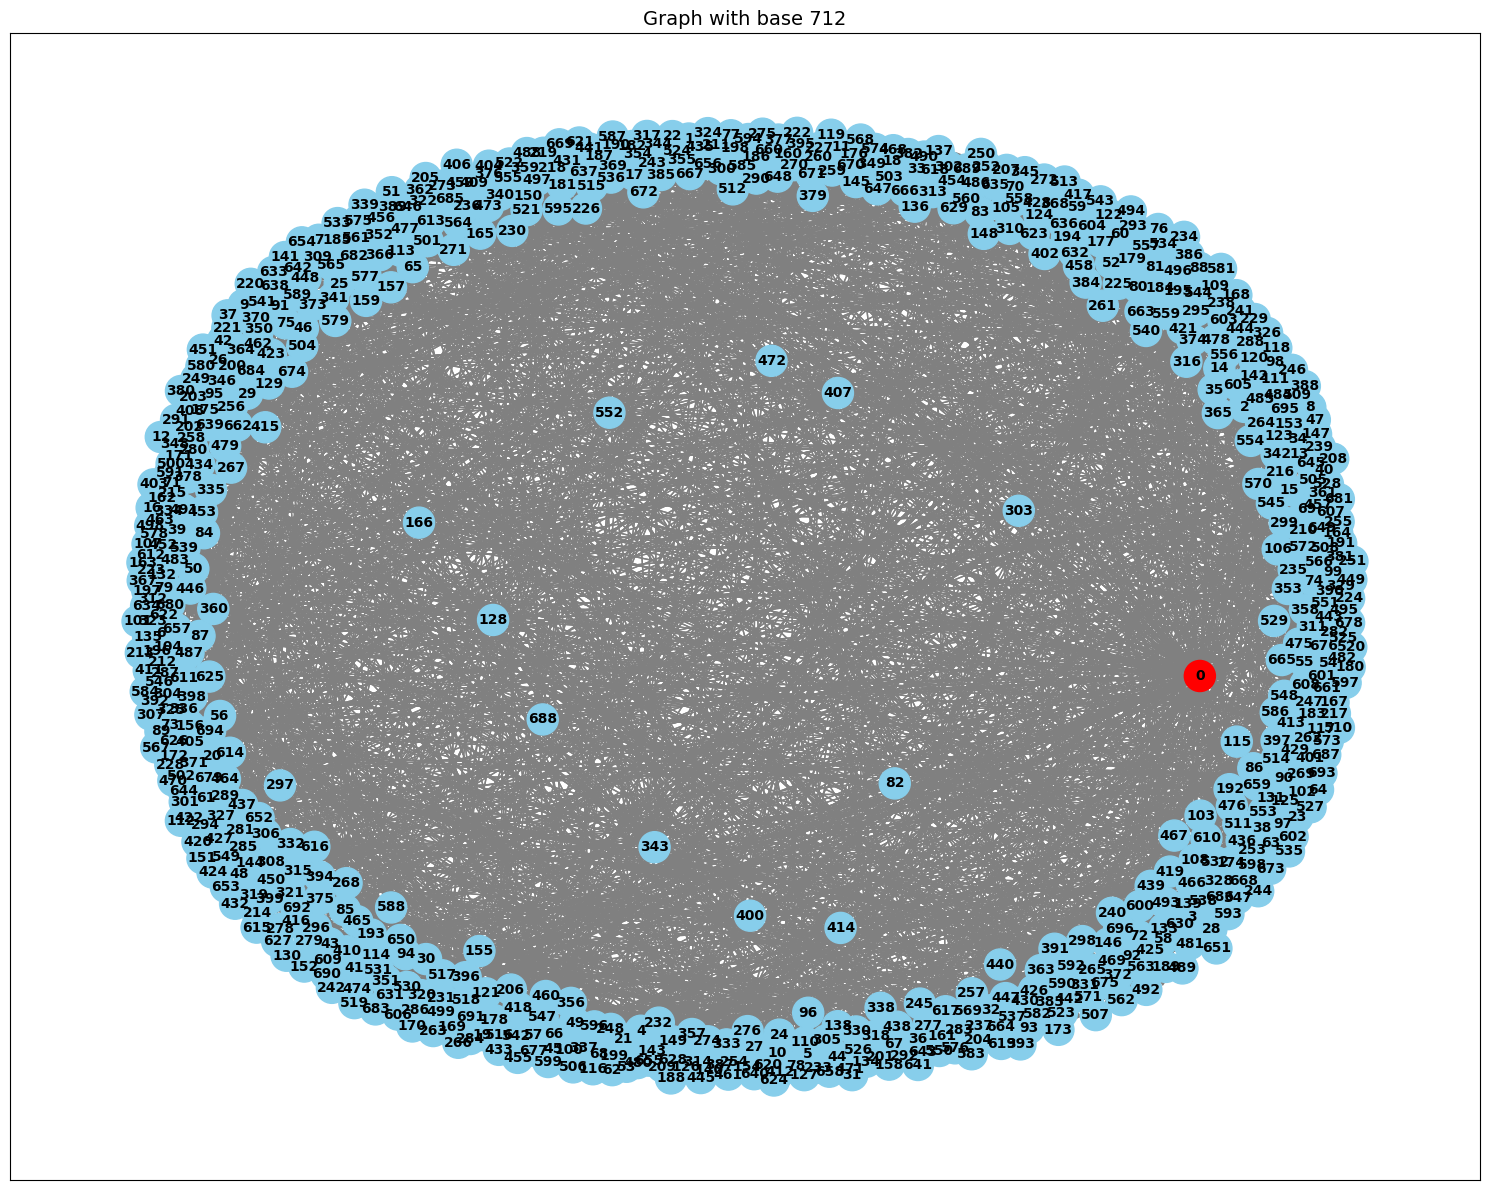

In [87]:
import matplotlib.pyplot as plt

#creo una lista delle basi da rimuovere 

remove_bases = [b for b in B if b != active_base]
#print(basi_da_rimuovere)

#creo il grafo senza le basi
G_sub = G.copy()
G_sub.remove_nodes_from(remove_bases)

plt.figure(figsize=(15, 12))

# k controlla la distanza tra i nodi 
pos = nx.spring_layout(G_sub, k=2, iterations=50, seed=42)

#colore rosso per la base 
node_colors = ['red' if n == active_base else 'skyblue' for n in G_sub.nodes()]

#0 se è la base altrimenti i valore del nodo
labels = {n: (0 if n == active_base else n) for n in G_sub.nodes()}

nx.draw_networkx(
    G_sub, 
    pos=pos,
    labels=labels, 
    node_size=500,  
    node_color=node_colors, 
    font_size=10,           
    font_weight='bold',
    edge_color='gray',
    arrows=True,
    arrowsize=15
)

plt.title(f"Graph with base {active_base}", fontsize=14)
#plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_335229/3293538406.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=12)
/tmp/ipykernel_335229/3293538406.py:53: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/davis/big-project-FOR/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


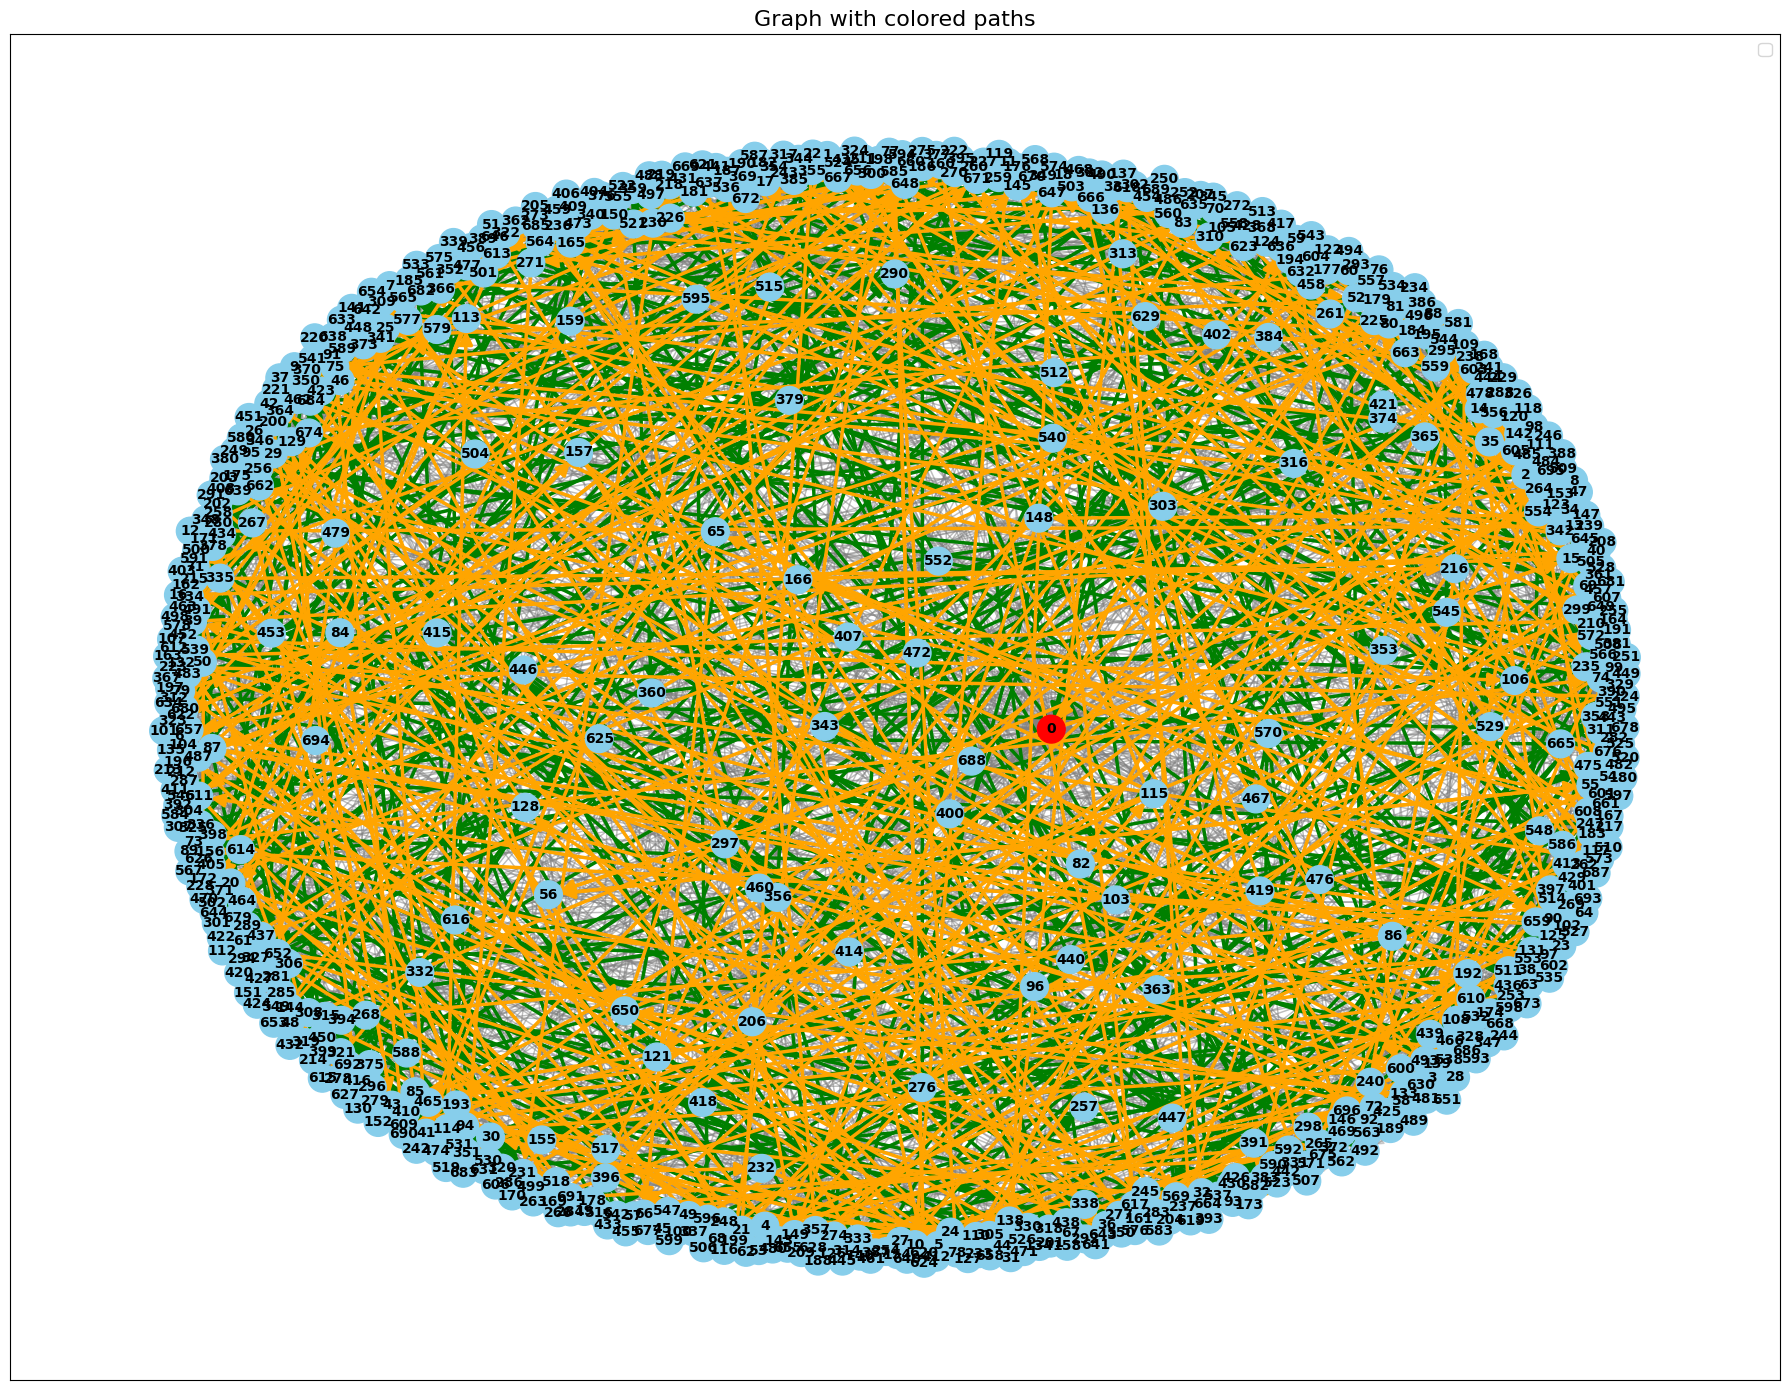

In [ ]:
import matplotlib.pyplot as plt

#creo una lista delle basi da rimuovere 

remove_bases = [b for b in B if b != active_base]
#print(basi_da_rimuovere)

#creo il grafo senza le basi
G_sub = G.copy()
G_sub.remove_nodes_from(remove_bases)

plt.figure(figsize=(18, 14))

#k controlla la distanza tra i nodi
pos = nx.spring_layout(G_sub, k=2.5, iterations=100, seed=42)


node_colors = ['red' if n == active_base else 'skyblue' for n in G_sub.nodes()]

#0 se è la base altrimenti i valore del nodo
labels = {n: (0 if n == active_base else n) for n in G_sub.nodes()}

# Estrai gli archi dai path
path_edges = [[] for _ in range(len(all_paths))] # lista di archi per ogni path
colors_path = plt.cm.rainbow(np.linspace(0, 1, len(all_paths)))  # colori per i due path

for idx, path in enumerate(all_paths):
    
    # all_paths contiene già liste di interi 
    # creo coppie di archi 
    for i in range(len(path) - 1):
        path_edges[idx].append((path[i], path[i+1]))

#disegno i nodi
nx.draw_networkx_nodes(G_sub, pos, node_size=400, node_color=node_colors)
nx.draw_networkx_labels(G_sub, pos, labels=labels, font_size=10, font_weight='bold')

#collego tutti i nodi
all_path_edges = set(path_edges[0] + path_edges[1])
other_edges = [e for e in G_sub.edges() if e not in all_path_edges]
nx.draw_networkx_edges(G_sub, pos, edgelist=other_edges, edge_color='gray', 
                       arrows=True, arrowsize=12, alpha=0.3)

#archi dei path 
for idx, edges in enumerate(path_edges):
    
    nx.draw_networkx_edges(G_sub, pos,  edgelist=edges, edge_color=colors_path[idx], 
                               arrows=True, arrowsize=20, width=2.5, 
                               label=f'Viaggio {idx+1}')

plt.title(f"Graph with colored paths", fontsize=16)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()